# TP Pandas de Eleve 1 et Eleve 2

Vous pouvez faire des cellules de type Markdown pour écrire du texte.
En mettant des # vous pouvez créer des titres et sous titre

## Todo:
* Télécharger un dataset sur data.gouv.fr
* Le référencer via son lien
* Etudier ce dataset sur pandas
* Garder les output des cellules
* Vérifier que toutes les cellules marchent
* Avant de rendre, faire Kernel -> Restart Kernel and run all cells
* Faire l'évaluation du cours

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Description du sujet

Nous nous sommes intéresser au jeu de donnée suivant : Enquête d'opinion internationale sur le changement climatique - Obs'COP - 2025
Le lien pour accéder à la base de donnée : https://www.data.gouv.fr/datasets/enquete-dopinion-internationale-sur-le-changement-climatique-obscop-2025

Nous avons commencer par supprimer les cases qui n'était que des traductions anglaises et modifer de le A avec accent avec un A sans accent. Par ailleurs nous avons convertit l'ensemble des valeurs en type int pour que cela soit plus facilement manipulable

In [4]:
df=pd.read_csv('ObsCop2025.csv', sep=';')
df=df.drop(columns=['Filter','Spatial perimeter','Population_en','Thematic','Question_en','Details of the question','Answer','Unit', 'Base_en'])
df.loc[df['Filtre']=='Âge', 'Filtre'] = 'Age'
df['Valeur']=df['Valeur'].apply(lambda x: float(str(x).replace(',', '.')))
df

C:\Users\clemj\AppData\Local\Temp\ipykernel_3152\1658957245.py:1: DtypeWarning: Columns (0: Détails de la question, 1: Details of the question, 2: Valeur) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('ObsCop2025.csv', sep=';')


,Année,Périmètre spatial,Filtre,Population,Thématique,Question,Détails de la question,Réponse,Valeur,Unité,Echantillon,Base
0,2025,Monde,dans l'ensemble,NaN,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Le chômage,38.0,%,23503.0,Tous
1,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Le chômage,26.0,%,1000.0,Tous
2,2025,Monde,Pays,Belgique,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Le chômage,17.0,%,1000.0,Tous
3,2025,Monde,Pays,Brésil,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Le chômage,51.0,%,1000.0,Tous
4,2025,Monde,Pays,Canada,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Le chômage,27.0,%,1000.0,Tous
...,...,...,...,...,...,...,...,...,...,...,...,...
146270,2025,Monde,ELEC1. Êtes-vous favorable ou défavorable à ce...,ST Défavorable,PARTIE D : LA PRISE EN COMPTE DU CHANGEMENT CL...,AIRCO. Disposez-vous d’un système de climatisa...,NaN,Ne sait pas,2.0,%,4682.0,Tous
146271,2025,Monde,"ELEC2. Selon vous, le fait que l’électricité r...",ST Important,PARTIE D : LA PRISE EN COMPTE DU CHANGEMENT CL...,AIRCO. Disposez-vous d’un système de climatisa...,NaN,Ne sait pas,1.0,%,16778.0,Tous
146272,2025,Monde,"ELEC2. Selon vous, le fait que l’électricité r...",ST Pas important,PARTIE D : LA PRISE EN COMPTE DU CHANGEMENT CL...,AIRCO. Disposez-vous d’un système de climatisa...,NaN,Ne sait pas,2.0,%,4013.0,Tous
146273,2025,Monde,"VEHELEC1. Personnellement, êtes-vous favorable...",ST Favorable,PARTIE D : LA PRISE EN COMPTE DU CHANGEMENT CL...,AIRCO. Disposez-vous d’un système de climatisa...,NaN,Ne sait pas,1.0,%,15862.0,Tous


rappel utilisation de la fonction .apply : 
lambda argument: expression_si_vrai if condition else expression_si_faux

In [5]:
Liste_question=df['Question'].unique()
Liste_filtre=df['Filtre'].unique()

In [6]:
#teste sur la réponse à la quesiton 1
len(df['Question'].unique())
Q=df['Question'][0]
df[(df['Filtre']=='Pays') & (df['Population']=='Australie') & (df['Question']==Q)]

,Année,Périmètre spatial,Filtre,Population,Thématique,Question,Détails de la question,Réponse,Valeur,Unité,Echantillon,Base
1,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Le chômage,26.0,%,1000.0,Tous
47,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,La pauvreté et les inégalités entre les citoyens,38.0,%,1000.0,Tous
93,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,"Le coût de la vie (inflation, pouvoir d’achat,...",81.0,%,1000.0,Tous
139,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Les taxes et impôts,26.0,%,1000.0,Tous
185,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,"L’éducation, l’école",22.0,%,1000.0,Tous
231,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Le système de santé,46.0,%,1000.0,Tous
277,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Les retraites,18.0,%,1000.0,Tous
323,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Immigration,29.0,%,1000.0,Tous
369,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Les atteintes à l’environnement,28.0,%,1000.0,Tous
415,2025,Monde,Pays,Australie,PARTIE A : PRÉOCCUPATIONS DES POPULATIONS,"A1BIS. Parmi cette liste, quels sont les sujet...",NaN,Le terrorisme,23.0,%,1000.0,Tous


44 questions différentes ont été posées. Des filtres différents ont était appliqués, pour chaque filtre une catégorie de polpulation a était étudié. Le tableau répertorie les taux des différentes réponses.

Dans un premier temps trions le tableau en enlevant les colonnes écrites en anglais


# Analyse 1 : inquiétude

Création d'un tableau comparant les réponses homme / femme à la question A1BIS : Parmi cette liste, quels sont les sujets qui vous préoccupent le plus ? 
Nous avons dans un premier temps effectuer un pivot puis représenter les résultats sous forme de graphe

In [7]:
df_utile1=df[(df['Question']==df['Question'][0]) & (df['Filtre']=='Genre')]
df_pivot1 = df_utile1.pivot_table(index='Réponse', columns='Population', values='Valeur', aggfunc='first')
df_pivot1

Population,Féminin,Masculin
Réponse,,
Autre,1.0,2.0
Immigration,24.0,26.0
La corruption,37.0,43.0
"La délinquance, la criminalité",41.0,37.0
La pauvreté et les inégalités entre les citoyens,47.0,42.0
Le changement climatique,44.0,42.0
Le chômage,40.0,36.0
Le coronavirus,14.0,12.0
"Le coût de la vie (inflation, pouvoir d’achat, etc…)",62.0,57.0


[]

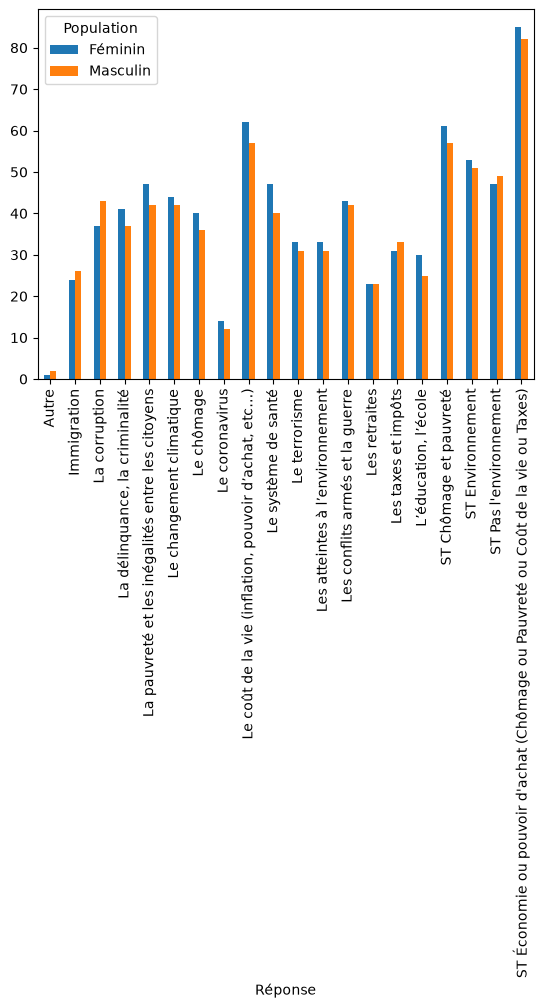

In [8]:
df_pivot1.plot(kind='bar')
plt.plot()

Conclusion : dans la plupart des domaine les femmes semblent être plus inquiètes sauf pour la corruption et l'immigration.

# Analyse 2 : climatoseptisme

On étudie maintenant le niveau de climto-septicisme question : 'B1/B3. Niveau de climato-scepticisme' en fonction des tranches d'âges.
Nous avons dans une premier temps effectué un pivot puis des camemberts

In [9]:
df_utile2=df[(df['Question']=='B1/B3. Niveau de climato-scepticisme') & (df['Filtre']=='Age')]

In [10]:
df_pivot2=df_utile2.pivot_table(index='Population', columns='Réponse', values='Valeur', aggfunc='first')
df_pivot2

Réponse,PAS climato-sceptique,ST Climato-sceptique,dont climato-sceptique dur,dont climato-sceptique mal informé
Population,,,,
16 à 24 ans,64.0,36.0,8.0,28.0
25 à 34 ans,62.0,38.0,8.0,30.0
35 à 44 ans,61.0,39.0,10.0,29.0
45 à 54 ans,64.0,36.0,11.0,25.0
55 ans et plus,63.0,37.0,11.0,26.0
St 16 à 34 ans,63.0,37.0,8.0,29.0
St 35 à 54 ans,62.0,38.0,11.0,27.0


In [11]:
Liste_Age=np.array(df_pivot2.index)
Liste_rep=['PAS climato-sceptique','ST Climato-sceptique']

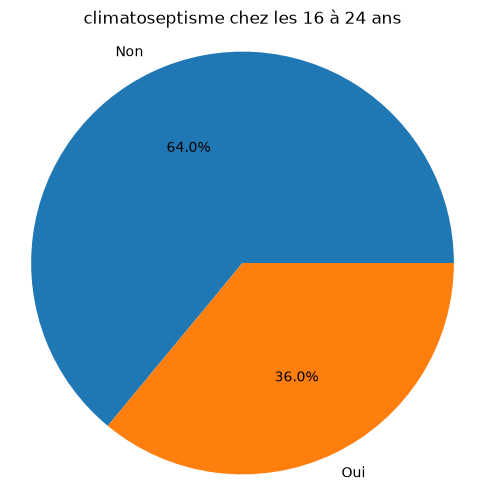

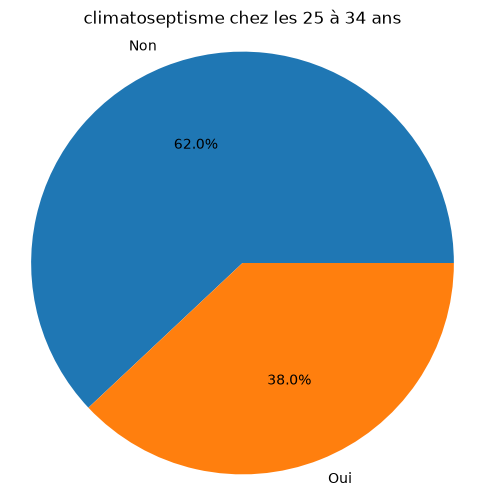

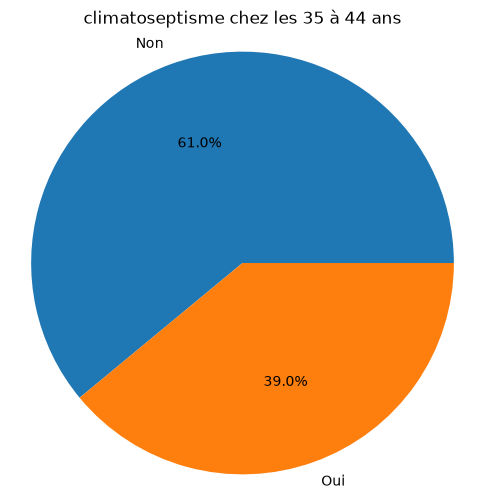

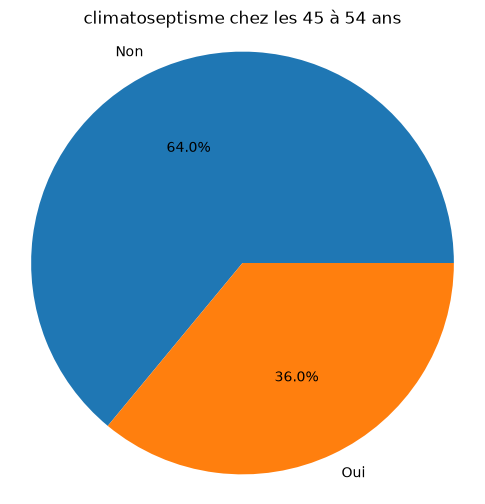

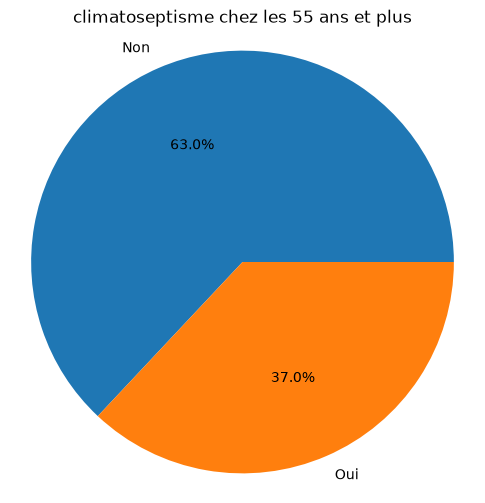

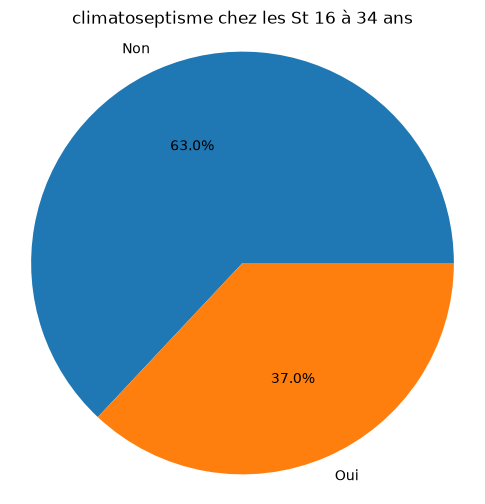

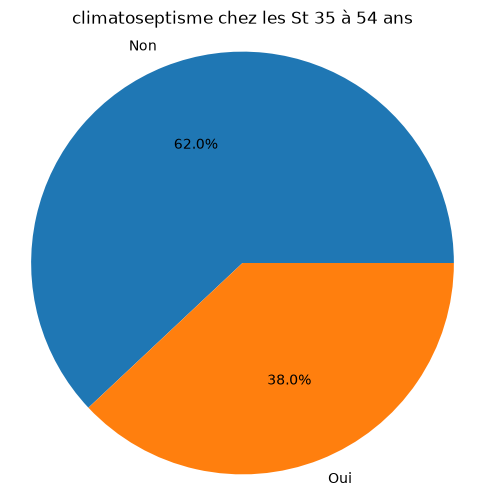

In [12]:
for A in Liste_Age:
    sizes = [df_pivot2.loc[A][Liste_rep[0]],df_pivot2.loc[A][Liste_rep[1]]]
    labels = ['Non', 'Oui']

    plt.figure(figsize=(6, 6))
    plt.pie(
        sizes,
        labels=labels,
        autopct="%1.1f%%",
        )
    plt.axis("equal")
    plt.title(f"climatoseptisme chez les {A}")
    plt.show()





Conclusion : Cette analyse montre que l'accès à l'information n'impacte en rien le climatoseptisme (probablement à cause de l'effet bulle connue sur les réseau sociaux et autres) puisque les proportionq semblent plutôt équivalentes alors que les jeunes ont maintenant beaucoup plus facilement accès à l'information. qu'avant.

# Analyse 3 : consommation de viande

On s'intéresse à la consommation de viande des foyer en fonction de leur revenue.

In [13]:
df_utile3=df[(df['Filtre']=='Revenu du foyer') & (df['Question']=='MEAT1. En moyenne, à quelle fréquence mangez-vous de la viande ou des repas à base de viande ?')]

df_pivot3=df_utile3.pivot_table(values='Valeur', index='Réponse', columns='Population')
df_pivot3

Population,Bas,Haut,Moyen
Réponse,,,
A chaque repas/deux fois par jour,13.0,16.0,13.0
Jamais,3.0,4.0,3.0
Moins d’une fois par semaine,17.0,10.0,12.0
"Plusieurs fois par semaine, mais moins d'une fois par jour",44.0,48.0,49.0
ST Hebdomadaire,80.0,86.0,85.0
ST Mange de la viande,97.0,96.0,97.0
ST Moins d'une fois par semaine ou jamais,20.0,14.0,15.0
ST Tous les jours,36.0,38.0,36.0
Une fois par jour,23.0,22.0,23.0


[]

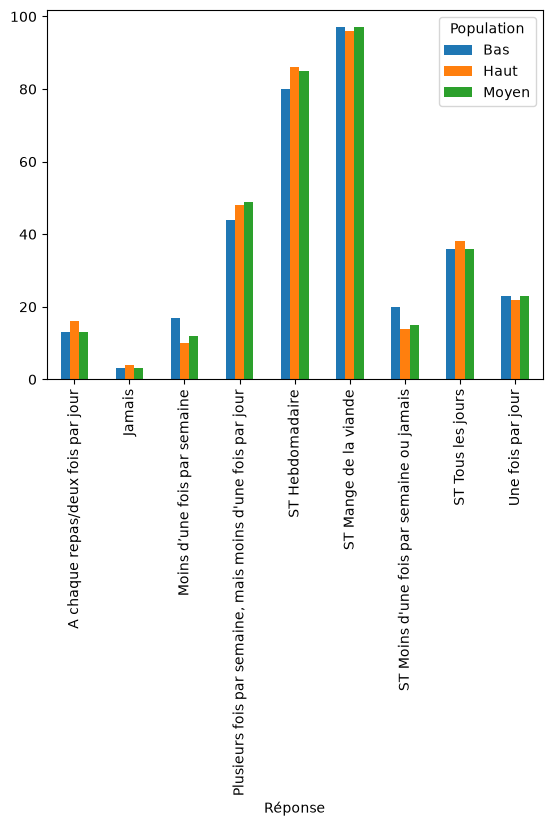

In [14]:
df_pivot3.plot(kind='bar')
plt.plot()

In [15]:
df_pivot32=df_pivot3.iloc[[0,1,2,3,8]]
df_pivot32

Population,Bas,Haut,Moyen
Réponse,,,
A chaque repas/deux fois par jour,13.0,16.0,13.0
Jamais,3.0,4.0,3.0
Moins d’une fois par semaine,17.0,10.0,12.0
"Plusieurs fois par semaine, mais moins d'une fois par jour",44.0,48.0,49.0
Une fois par jour,23.0,22.0,23.0


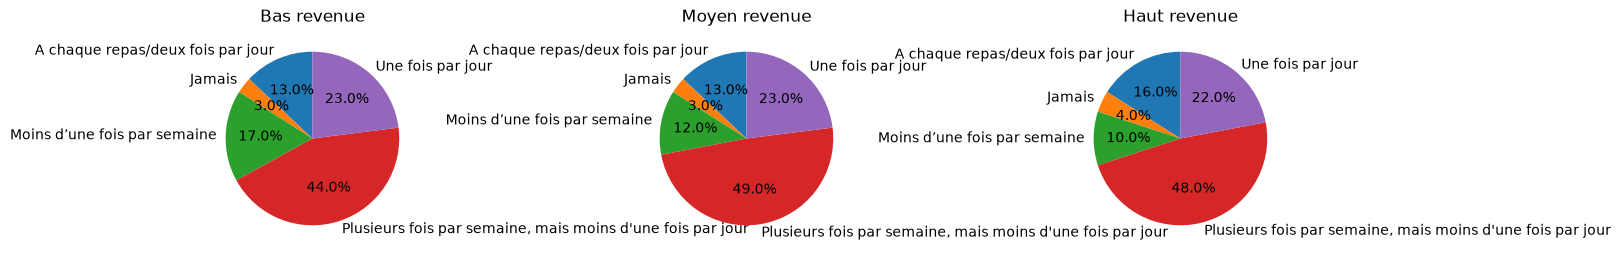

In [16]:
label=np.array(df_pivot32.index)
dataB=np.array(df_pivot32['Bas'])
dataH=np.array(df_pivot32['Haut'])
dataM=np.array(df_pivot32['Moyen'])

fig, axs =plt.subplots(1,3, figsize=(14,14))

axs[0].pie(dataB, labels=label, autopct='%1.1f%%', startangle=90)
axs[0].set_title('Bas revenue')

axs[1].pie(dataM, labels=label, autopct='%1.1f%%', startangle=90)
axs[1].set_title('Moyen revenue')

axs[2].pie(dataH, labels=label, autopct='%1.1f%%', startangle=90)
axs[2].set_title('Haut revenue')

plt.subplots_adjust(hspace=0.5, wspace=1)
plt.show()

Conclusion : cette analyse permet de se rendre compte de la chose suivante : bien que la viande soit devenu un aliment cher, il n'y a pas vraiment de corrélation entre le revenue d'un foyer et sa consommation de viande.

# Analyse 4 : 

In [17]:
df_utile4=df[(df['Question']=='PLANE2. En général, ces dernières années, à quelle fréquence prenez-vous l’avion ?') & (df['Filtre']=='Revenu du foyer')]

In [18]:
df_pivot4=df_utile4.pivot_table(values='Valeur', index='Réponse', columns='Population')
df_pivot4

Population,Bas,Haut,Moyen
Réponse,,,
Jamais,12.5,5.0,9.0
Moins souvent,31.0,21.5,29.5
N'a jamais voyagé en avion,33.0,11.0,16.0
Plusieurs fois par an,10.0,27.0,16.5
Plusieurs fois par mois,1.5,3.0,1.0
ST Au moins plusieurs fois,11.5,30.0,17.5
ST Au moins une fois par an,40.0,68.0,53.5
ST Moins souvent ou jamais,43.5,26.5,38.5
Une à deux fois par an,28.5,38.0,36.0


In [19]:
df_pivot42=df_pivot4.iloc[[0,1,2,3,4,8]]
df_pivot42

Population,Bas,Haut,Moyen
Réponse,,,
Jamais,12.5,5.0,9.0
Moins souvent,31.0,21.5,29.5
N'a jamais voyagé en avion,33.0,11.0,16.0
Plusieurs fois par an,10.0,27.0,16.5
Plusieurs fois par mois,1.5,3.0,1.0
Une à deux fois par an,28.5,38.0,36.0


<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data: 'DataParamType' = None, **kwargs) -> 'list[Line2D]'>

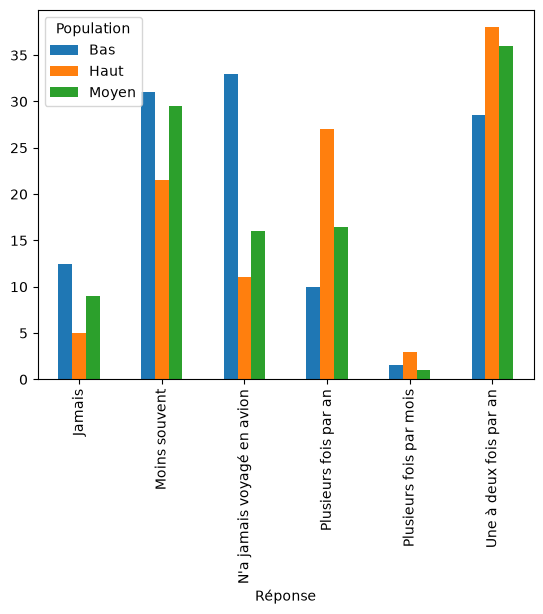

In [20]:
df_pivot42.plot(kind='bar')
plt.plot

Conclusion : on voit apparaitre une réelle corrélation entre la fréquence de voyage en avion et le revenue

Il existe ce type de donné pour les années précédantes. Il serait pertinent d'importer celle-ci et de créer des graphe représentant l'évolution de certaines grandeurs aucours du temps. 

# Analyse 5 : Géographie et impacte climatique

In [21]:
df_utile5=df[(df['Question']=='B7. Globalement, diriez-vous que, dans votre région, vous avez déjà constaté les effets du changement climatique ?') & (df['Filtre']=='Pays')]
df_utile5 = df_utile5[~df_utile5['Population'].str.startswith('ST', na=False)]

In [22]:
df_pivot5=df_utile5.pivot_table(values='Valeur', index='Population', columns='Réponse')
df_pivot5

Réponse,Ceux qui ne vivent pas un changement climatique,Ne sait pas,"Non, pas du tout","Non, pas vraiment","Oui, plutôt","Oui, tout à fait",SI OUI,ST NON
Population,,,,,,,,
Afrique du Sud,2.0,2.0,2.0,9.0,34.0,51.0,85.0,11.0
Allemagne,2.0,5.0,5.0,19.0,45.0,24.0,69.0,24.0
Arabie Saoudite,1.0,12.0,2.0,14.0,39.0,32.0,71.0,16.0
Australie,7.0,6.0,6.0,18.0,39.0,24.0,63.0,24.0
Belgique,2.0,6.0,3.0,23.0,46.0,20.0,66.0,26.0
Brésil,1.0,4.0,2.0,8.0,29.0,56.0,85.0,10.0
Canada,3.0,4.0,3.0,14.0,44.0,32.0,76.0,17.0
Chili,3.0,1.0,1.0,6.0,35.0,54.0,89.0,7.0
Chine,1.0,16.0,2.0,6.0,44.0,31.0,75.0,8.0


In [23]:
df_pivot52=df_pivot5['Oui, tout à fait'].sort_values(ascending=False)
df_pivot52

Population
Colombie               69.0
Mexique                63.0
Nigeria                58.0
Maroc                  57.0
Turquie                57.0
Brésil                 56.0
Indonésie              56.0
Chili                  54.0
Inde                   53.0
Afrique du Sud         51.0
Égypte                 49.0
Émirats Arabes Unis    42.0
Japon                  35.0
Espagne                34.0
Singapour              33.0
Italie                 32.0
Arabie Saoudite        32.0
Canada                 32.0
Chine                  31.0
France                 29.0
États-Unis             29.0
Corée du Sud           26.0
Royaume-Uni            26.0
Allemagne              24.0
Australie              24.0
Norvège                23.0
Pologne                22.0
Belgique               20.0
Suède                  17.0
République Tchéque     16.0
Name: Oui, tout à fait, dtype: float64

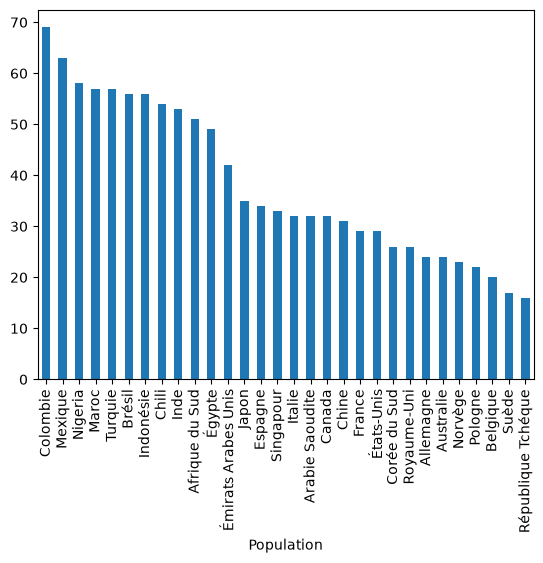

In [24]:
df_pivot52.plot(kind='bar')
plt.show()

On remarque ici de grande différence entre les pays ayant ressenti de nette changement à cause du changement climatique. Il serait pertinent de reporter ces valeurs sur une carte pour savoir si le phénomène de Jancovici concernant les hausses des températures est réelle : il y aurait plus de variation de température et à forciorie du climat dans les zones des pôles, notamment au pôle nord (puisque moins d'océan), qu'à l'équateur

# Comparaison temporel

In [28]:
df2025=pd.read_csv('ObsCop2025.csv', sep=';')
df2025=df2025.drop(columns=['Filter','Spatial perimeter','Population_en','Thematic','Question_en','Details of the question','Answer','Unit', 'Base_en'])
df2025.loc[df2025['Filtre']=='Âge', 'Filtre'] = 'Age'
df2025['Valeur']=df2025['Valeur'].apply(lambda x: float(str(x).replace(',', '.')))


df2025_utile=df2025[(df2025['Filtre']==" dans l'ensemble") & (df2025['Question']=='B1/B3. Niveau de climato-scepticisme')]
df2025_pivot=df2025_utile.pivot_table(values='Valeur', index='Réponse', columns='Filtre')
df2025_pivot

C:\Users\clemj\AppData\Local\Temp\ipykernel_3152\1629565928.py:1: DtypeWarning: Columns (0: Détails de la question, 1: Details of the question, 2: Valeur) have mixed types. Specify dtype option on import or set low_memory=False.
  df2025=pd.read_csv('ObsCop2025.csv', sep=';')


Filtre,dans l'ensemble
Réponse,
PAS climato-sceptique,63.0
ST Climato-sceptique,37.0
dont climato-sceptique dur,10.0
dont climato-sceptique mal informé,27.0


In [30]:
df2024=pd.read_csv("ObsCop2024.csv", sep=';')
df2024=df2024.drop(columns=['Filter','Spatial perimeter','Population_en','Thematic','Question_en','Details of the question','Answer','Unit', 'Base_en'])
df2024.loc[df2024['Filtre']=='Âge', 'Filtre'] = 'Age'
df2024['Valeur']=df2024['Valeur'].apply(lambda x: float(str(x).replace(',', '.')))

df2024_utile=df2024[(df2024['Filtre']==" dans l'ensemble") & (df2024['Question']=='B1/B3. Niveau de climato-scepticisme')]
df2024_pivot=df2024_utile.pivot_table(values='Valeur', index='Réponse', columns='Filtre')
df2024_pivot

C:\Users\clemj\AppData\Local\Temp\ipykernel_3152\3480433852.py:1: DtypeWarning: Columns (0: Détails de la question, 1: Details of the question, 2: Valeur) have mixed types. Specify dtype option on import or set low_memory=False.
  df2024=pd.read_csv("ObsCop2024.csv", sep=';')


Filtre,dans l'ensemble
Réponse,
PAS climato-sceptique,62.0
ST Climato-sceptique,38.0
dont climato-sceptique dur,10.0
dont climato-sceptique mal informé,28.0


In [32]:
df2023=pd.read_csv("ObsCop2023.csv", sep=';')
df2023=df2023.drop(columns=['Filter','Spatial perimeter','Population_en','Thematic','Question_en','Details of the question','Answer','Unit', 'Base_en'])
df2023.loc[df2023['Filtre']=='Âge', 'Filtre'] = 'Age'
df2023['Valeur']=df2023['Valeur'].apply(lambda x: float(str(x).replace(',', '.')))
df2023=df2023.rename(columns={'R�ponse': 'Réponse'})

df2023_utile=df2023[(df2023['Filtre']=='ENSEMBLE\r\n ') & (df2023['Question']=='B1/B3. Niveau de climato-scepticisme')]
df2023_pivot=df2023_utile.pivot_table(values='Valeur', index='Réponse', columns='Filtre')
df2023_pivot



C:\Users\clemj\AppData\Local\Temp\ipykernel_3152\3200886605.py:1: DtypeWarning: Columns (0: Valeur) have mixed types. Specify dtype option on import or set low_memory=False.
  df2023=pd.read_csv("ObsCop2023.csv", sep=';')


Filtre,ENSEMBLE\r\n
Réponse,
Pas climato-sceptique,64.0
ST Climato-sceptique,36.0
dont climato-sceptique dur,9.0
dont climato-sceptique mal inform�,27.0


In [33]:
df2022=pd.read_csv("ObsCop2022.csv", sep=';')
df2022=df2022.drop(columns=['Filter','Spatial perimeter','Population_en','Thematic','Question_en','Details of the question','Answer','Unit', 'Base_en'])
df2022.loc[df2022['Filtre']=='Âge', 'Filtre'] = 'Age'
df2022['Valeur']=df2022['Valeur'].apply(lambda x: float(str(x).replace(',', '.')))
df2022=df2022.rename(columns={'R�ponse': 'Réponse'})

df2022_utile=df2022[(df2022['Filtre']=='ENSEMBLE\r\n ') & (df2022['Question']=='B1/B3. Niveau de climato-scepticisme')]
df2022_pivot=df2022_utile.pivot_table(values='Valeur', index='Réponse', columns='Filtre')
df2022_pivot


C:\Users\clemj\AppData\Local\Temp\ipykernel_3152\1185134416.py:1: DtypeWarning: Columns (0: Valeur) have mixed types. Specify dtype option on import or set low_memory=False.
  df2022=pd.read_csv("ObsCop2022.csv", sep=';')


Filtre,ENSEMBLE\r\n
Réponse,
Pas climato-sceptique,63.0
ST Climato-sceptique,37.0
dont climato-sceptique dur,9.0
dont climato-sceptique mal inform�,28.0


In [39]:
df2021=pd.read_csv("ObsCop2021.csv", sep=';')
df2021=df2021.drop(columns=['Filter','Spatial perimeter','Population_en','Thematic','Question_en','Details of the question','Answer','Unit', 'Base_en'])
df2021.loc[df2021['Filtre']=='Âge', 'Filtre'] = 'Age'
df2021['Valeur']=df2021['Valeur'].apply(lambda x: float(str(x).replace(',', '.')))
df2021=df2021.rename(columns={'R�ponse': 'Réponse'})

df2021_utile=df2021[(df2021['Filtre']=='ENSEMBLE ') & (df2021['Question']=='B1/B3. Niveau de climato-scepticisme')]
df2021_pivot=df2021_utile.pivot_table(values='Valeur', index='Réponse', columns='Filtre')
df2021_pivot


Filtre,ENSEMBLE
Réponse,
PAS climato-sceptique,66.0
ST CLIMATO-SCEPTIQUE,34.0
dont climato-sceptique dur,9.0
dont les sceptiques du r�chauffement climatique mal inform�s,25.0


In [72]:
df2020=pd.read_csv("ObsCop2020.csv", sep=';')
df2020=df2020.drop(columns=['Filter','Spatial perimeter','Population_en','Thematic','Question_en','Details of the question','Answer','Unit', 'Base_en'])
df2020.loc[df2020['Filtre']=='Âge', 'Filtre'] = 'Age'
df2020['Valeur']=df2020['Valeur'].apply(lambda x: float(str(x).replace(',', '.')))
df2020=df2020.rename(columns={'R�ponse': 'Réponse'})

df2020_utile=df2020[(df2020['Filtre']=='ENSEMBLE') & (df2020['Question']=='B1/B3. Niveau de climato-scepticisme')]
df2020_pivot=df2020_utile.pivot_table(values='Valeur', index='Réponse', columns='Filtre')
df2020_pivot


Filtre,ENSEMBLE
Réponse,
PAS climato-sceptique,68.0
ST Climato-sceptique,32.0
dont climato-sceptique consid�rant que le changement climatique n'est pas d'origine humaine,25.0
dont climato-sceptique dur,7.0


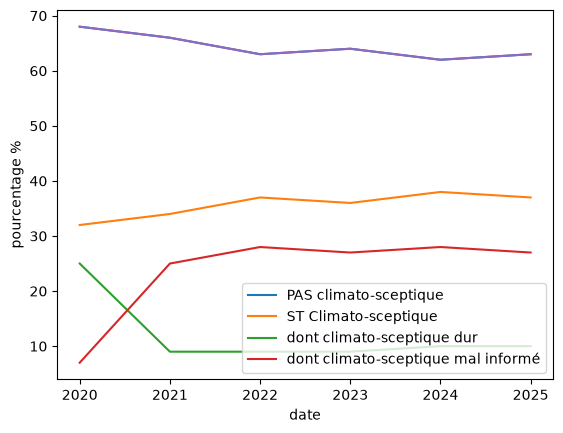

In [71]:
V={}
R=np.array(df2025_pivot.index)
DF=[df2020_pivot,df2021_pivot,df2022_pivot,df2023_pivot,df2024_pivot,df2025_pivot]
Date=np.arange(2020,2026)

for i in range(4):
    V[i]=[]
    for D in DF:
        V[i]+=[D.iloc[i].values[0]]
    V[i]=np.array(V[i])
    plt.plot(Date, V[i], label=R[i])

plt.legend()
plt.ylabel('pourcentage %')
plt.xlabel('date')
plt.plot(Date,V[0])
plt.show()

Voici les graphiques reprédentant les différentes formes de climatosceptisme. Les réponses de 2020 ne sont pas cohérentes pour les courbes verte et rouge puisque d'autres questions ont été posé à ce niveau 